# Projeto 1 – Modelação: Classificação
## Identificar as patologias de cada bebé em cada dia (Grupo 5)

Este notebook implementa a parte de **classificação** dos capítulos 5 e 6 do relatório. Parte de `dataset_classificacao.csv` (notebook 02) e segue a estrutura do demo da aula (`demo_class.ipynb`): árvore de decisão, rede neuronal e Random Forest, avaliados com `classification_report`.

O nosso problema é diferente do Iris em três pontos, e cada um muda o código:

| Demo da aula (Iris) | O nosso problema | O que muda no código |
|---|---|---|
| Uma classe por flor | Um bebé pode ter várias patologias no mesmo dia (**multi-rótulo**) | Um classificador binário (sim/não) **por patologia**: DMH, icterícia, anemia, CMV e "outra" |
| Classes equilibradas | DMH em 53% dos dias, CMV em 7% | `class_weight="balanced"`, F1-macro em vez de exatidão, limiar de decisão ajustado |
| Flores independentes | Vários dias do mesmo bebé | Validação **agrupada por bebé** (`StratifiedGroupKFold`): o mesmo bebé nunca está no treino e no teste |

| Secção do relatório | O que este notebook faz |
|---|---|
| 5.1 Selecionar técnicas | Algoritmos e dois cenários de variáveis |
| 5.2 Desenho de teste | Validação agrupada por bebé, métricas, baseline |
| 5.3 Construir modelos | Baseline, árvore, regressão logística, Random Forest, Gradient Boosting, rede neuronal |
| 5.4 Avaliar modelos | Tabelas por patologia, ajuste do limiar, matrizes de confusão, variáveis importantes |
| 6.1 Avaliar resultados | Comparação com a Tabela 8 |

**A decidir pelo grupo (ver 5.1):** o relatório define a classificação "a partir dos sinais vitais desse dia" (cenário A). Testamos também um cenário B que junta as patologias registadas **no dia anterior**. Os resultados são muito diferentes, e a escolha tem de ficar justificada no relatório. Confirmem também na página do Kaggle qual é o formato da submissão.

## 0. Configuração

In [1]:
# --- Bibliotecas ---
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib                                   # guardar o modelo final (Projeto 2)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- Pastas (mesma lógica dos notebooks 01 e 02) ---
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC_DIR = ROOT / "data" / "processed"                      # saída do notebook 02
MODEL_DIR = ROOT / "models"                                  # modelos finais para o BI
FIG_DIR = ROOT / "reports" / "figures" / "modeling_classificacao"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42                                                    # mesma semente em todo o lado (reprodutibilidade)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

ALVOS = ["pat_dmh", "pat_ictericia", "pat_anemia", "pat_cmv", "pat_outra"]
N_FOLDS = 5
SEMENTES = [42, 7, 2027]        # repetimos a validação com 3 partições diferentes e fazemos a média

## Carregar os dados

Uma linha por bebé e dia com sinais vitais. `episodio` e `data` identificam a linha e **não** entram no modelo; `episodio` é usado só para agrupar a validação.

In [2]:
d = pd.read_csv(PROC_DIR / "dataset_classificacao.csv", parse_dates=["data"])
grupos = d["episodio"]
print(f"{len(d)} dias-bebé de {grupos.nunique()} bebés")
resumo = pd.DataFrame({"dias_com_patologia": d[ALVOS].sum(),
                       "prevalencia_%": (d[ALVOS].mean() * 100).round(1),
                       "bebes_com_patologia": [d.loc[d[a] == 1, "episodio"].nunique() for a in ALVOS]})
resumo

449 dias-bebé de 47 bebés


,dias_com_patologia,prevalencia_%,bebes_com_patologia
pat_dmh,236,52.6,26
pat_ictericia,117,26.1,20
pat_anemia,43,9.6,6
pat_cmv,32,7.1,6
pat_outra,80,17.8,7


## 5.1 Selecionar técnicas de modelação

### Algoritmos (Tabela 13 do relatório, mais os do demo)

| Modelo | Porquê |
|---|---|
| Baseline: ao acaso segundo a prevalência | O valor a bater (`DummyClassifier(strategy="stratified")`) |
| Árvore de decisão (profundidade 4) | Do demo; regras legíveis |
| Regressão logística | Simples, estável com poucos dados, coeficientes interpretáveis |
| Random Forest | Do demo; capta relações não lineares |
| Gradient Boosting (`HistGradientBoosting`) | Aceita valores em falta sem imputação |
| Rede neuronal (MLP) | Do demo; pequena e com normalização |

Os valores em falta (os `_delta` do primeiro dia de cada bebé e 2 tendências) são imputados com a mediana **do treino**, dentro do *pipeline*, como diz a secção 4.5 do relatório.

### Dois cenários de variáveis

- **Cenário A — só sinais vitais** (como no relatório): as 26 variáveis do `dataset_classificacao.csv`.
- **Cenário B — sinais vitais + patologias do dia anterior**: junta 6 variáveis, uma por grupo de patologia (`ontem_<grupo>` = 1 se estava registada no dia de calendário anterior) e `ontem_registo` (houve algum registo de patologia no dia anterior). Respeita a regra 4.1 de nunca usar dias futuros, e corresponde ao uso real: de manhã, a equipa já conhece os diagnósticos de ontem e quer saber os de hoje.

As variáveis do cenário B são construídas a partir de `patologias_limpo.csv`, incluindo os dias com patologia sem sinais vitais. Se o grupo adotar este cenário, o passo deve passar para o notebook 02 (secção 4.3).

In [3]:
pat = pd.read_csv(PROC_DIR / "patologias_limpo.csv", parse_dates=["data"])
ontem = (pat.drop_duplicates(["episodio", "data", "grupo"]).assign(valor=1)
         .pivot_table(index=["episodio", "data"], columns="grupo", values="valor", fill_value=0)
         .reindex(columns=["dmh", "ictericia", "anemia", "cmv", "outra"], fill_value=0)
         .add_prefix("ontem_").reset_index())
ontem["data"] = ontem["data"] + pd.Timedelta(days=1)      # o registo de ontem fica associado a hoje
ontem["ontem_registo"] = 1
d = d.merge(ontem, on=["episodio", "data"], how="left")
VARS_ONTEM = [c for c in d.columns if c.startswith("ontem_")]
d[VARS_ONTEM] = d[VARS_ONTEM].fillna(0).astype(int)

VARS_A = [c for c in d.columns if c not in ["episodio", "data"] + ALVOS + VARS_ONTEM]
VARS_B = VARS_A + VARS_ONTEM
print(f"Cenário A: {len(VARS_A)} variáveis | Cenário B: {len(VARS_B)} variáveis")

# Quanto é que uma patologia de ontem "anuncia" a de hoje?
persist = pd.DataFrame({a: {"P(hoje | ontem)": d.loc[d[f"ontem_{a[4:]}"] == 1, a].mean(),
                            "P(hoje | não ontem)": d.loc[d[f"ontem_{a[4:]}"] == 0, a].mean()} for a in ALVOS}).T
(persist * 100).round(1)

Cenário A: 26 variáveis | Cenário B: 32 variáveis


,P(hoje | ontem),P(hoje | não ontem)
pat_dmh,94.0,13.4
pat_ictericia,89.7,6.1
pat_anemia,94.6,1.9
pat_cmv,86.2,1.7
pat_outra,96.1,1.6


## 5.2 Gerar o desenho de teste

- **Validação:** `StratifiedGroupKFold` com 5 partições. Cada bebé fica inteiro numa só partição, e a proporção de dias com a patologia é parecida em todas. Repetimos com 3 sementes e fazemos a média, porque com poucos bebés com CMV ou anemia o resultado depende muito de como caem nas partições.
- **Previsões fora da amostra:** para cada dia guardamos a probabilidade prevista pelo modelo treinado **sem esse bebé**.
- **Métricas:** F1 por patologia e F1-macro (principal); precisão, *recall*, ROC-AUC e kappa de Cohen. A exatidão aparece só no `classification_report`.
- **Limiar:** por defeito um dia é positivo se a probabilidade for ≥ 0,5. Na secção 5.4 ajustamos o limiar de cada patologia **só com os dados de treino**.

In [4]:
def prob_fora_amostra(fabrica, X, y, semente):
    # Probabilidade de cada dia, prevista por um modelo que não viu esse bebé
    p = np.zeros(len(y))
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semente)
    for tr, ts in cv.split(X, y, grupos):
        m = fabrica().fit(X.iloc[tr], y[tr])
        p[ts] = m.predict_proba(X.iloc[ts])[:, 1]
    return p

def metricas(y, p, limiar=0.5):
    pr = (p >= limiar).astype(int)
    return {"F1": f1_score(y, pr, zero_division=0), "precisao": precision_score(y, pr, zero_division=0),
            "recall": recall_score(y, pr), "AUC": roc_auc_score(y, p), "kappa": cohen_kappa_score(y, pr)}

def avaliar(nome, fabrica, variaveis):
    # Média das métricas nas 3 sementes, para cada patologia
    linhas, probs = [], {}
    for a in ALVOS:
        y = d[a].to_numpy()
        ps = [prob_fora_amostra(fabrica, d[variaveis], y, s) for s in SEMENTES]
        probs[a] = ps
        m = pd.DataFrame([metricas(y, p) for p in ps]).mean()
        linhas.append({"modelo": nome, "patologia": a[4:], **m.round(3).to_dict()})
    return pd.DataFrame(linhas), probs

## 5.3 Construir os modelos

Cada "fábrica" cria um modelo novo e por treinar; é chamada uma vez por partição, por patologia e por semente.

In [5]:
imputar = lambda: SimpleImputer(strategy="median")
MODELOS = {
    "Baseline (prevalência)": lambda: DummyClassifier(strategy="stratified", random_state=SEED),
    "Árvore de decisão": lambda: make_pipeline(imputar(), tree.DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=SEED)),
    "Regressão logística": lambda: make_pipeline(imputar(), StandardScaler(), LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=2000)),
    "Random Forest": lambda: make_pipeline(imputar(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": lambda: HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=150, class_weight="balanced", random_state=SEED),
    "Rede neuronal": lambda: make_pipeline(imputar(), StandardScaler(), MLPClassifier(
        hidden_layer_sizes=[8], alpha=1.0, max_iter=3000, random_state=SEED)),
}

por_patologia, probs = [], {}
for cenario, variaveis in [("A", VARS_A), ("B", VARS_B)]:
    for nome, fabrica in MODELOS.items():
        t, probs[(cenario, nome)] = avaliar(nome, fabrica, variaveis)
        t.insert(0, "cenario", cenario)
        por_patologia.append(t)
        print(f"Cenário {cenario} | {nome:<24} F1-macro = {t['F1'].mean():.3f}")
por_patologia = pd.concat(por_patologia, ignore_index=True)

Cenário A | Baseline (prevalência)   F1-macro = 0.225
Cenário A | Árvore de decisão        F1-macro = 0.320
Cenário A | Regressão logística      F1-macro = 0.309
Cenário A | Random Forest            F1-macro = 0.279
Cenário A | Gradient Boosting        F1-macro = 0.290
Cenário A | Rede neuronal            F1-macro = 0.297
Cenário B | Baseline (prevalência)   F1-macro = 0.225
Cenário B | Árvore de decisão        F1-macro = 0.659
Cenário B | Regressão logística      F1-macro = 0.793
Cenário B | Random Forest            F1-macro = 0.602
Cenário B | Gradient Boosting        F1-macro = 0.738
Cenário B | Rede neuronal            F1-macro = 0.764


## 5.4 Avaliar os modelos

### Resumo por modelo e cenário (Tabela 30 do relatório)

F1-macro é a média do F1 das 5 patologias. As outras colunas também são médias das 5.

,cenario,modelo,F1_macro,precisao,recall,AUC,kappa
0,A,Baseline (prevalência),0.225,0.225,0.227,0.501,0.003
1,A,Árvore de decisão,0.320,0.259,0.455,0.547,0.075
2,A,Regressão logística,0.309,0.253,0.413,0.495,0.054
3,A,Random Forest,0.279,0.293,0.275,0.516,0.106
4,A,Gradient Boosting,0.290,0.270,0.316,0.513,0.090
5,A,Rede neuronal,0.297,0.314,0.290,0.541,0.127
6,B,Baseline (prevalência),0.225,0.225,0.227,0.501,0.003
7,B,Árvore de decisão,0.659,0.613,0.725,0.837,0.583
8,B,Regressão logística,0.793,0.759,0.848,0.920,0.737
9,B,Random Forest,0.602,0.736,0.530,0.838,0.558


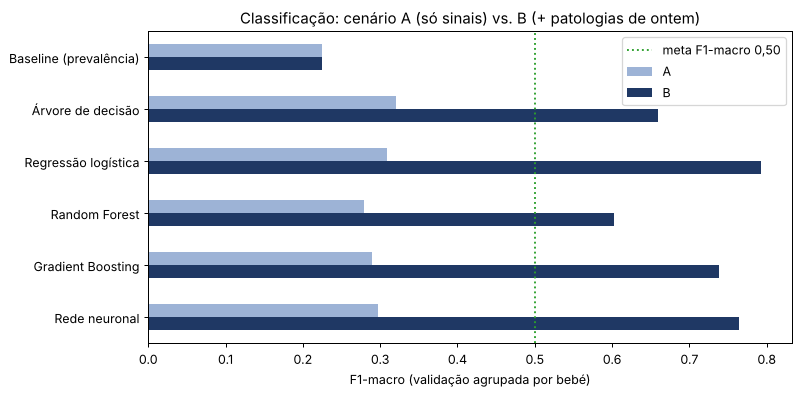

In [6]:
resumo_modelos = (por_patologia.groupby(["cenario", "modelo"], sort=False)[["F1", "precisao", "recall", "AUC", "kappa"]]
                  .mean().round(3).rename(columns={"F1": "F1_macro"}).reset_index())
display(resumo_modelos)
resumo_modelos.to_csv(FIG_DIR / "tabela_classificacao_modelos.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
pivot = resumo_modelos.pivot(index="modelo", columns="cenario", values="F1_macro").loc[list(MODELOS)]
pivot.plot.barh(ax=ax, color=["#9db3d6", "#1f3864"])
ax.axvline(0.50, color="tab:green", ls=":", label="meta F1-macro 0,50")
ax.invert_yaxis()
ax.set(xlabel="F1-macro (validação agrupada por bebé)", ylabel="", title="Classificação: cenário A (só sinais) vs. B (+ patologias de ontem)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_f1_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

### Detalhe por patologia

Para cada cenário mostramos o melhor modelo. No cenário A, a AUC de CMV fica abaixo de 0,5. Isto não quer dizer que o modelo aprenda "ao contrário": como só há poucos bebés com CMV, quando um deles sai para teste o treino fica com ainda menos casos, e o modelo associa CMV às características dos outros bebés. Na prática, os sinais vitais não distinguem CMV.

In [7]:
melhor = resumo_modelos.loc[resumo_modelos.groupby("cenario")["F1_macro"].idxmax(), ["cenario", "modelo"]]
for _, r in melhor.iterrows():
    print(f"\nCenário {r.cenario} — melhor modelo: {r.modelo}")
    display(por_patologia.query("cenario == @r.cenario and modelo == @r.modelo").drop(columns=["cenario", "modelo"]))


Cenário A — melhor modelo: Árvore de decisão


,patologia,F1,precisao,recall,AUC,kappa
5,dmh,0.636,0.592,0.686,0.590,0.164
6,ictericia,0.499,0.378,0.738,0.689,0.237
7,anemia,0.210,0.138,0.442,0.570,0.075
8,cmv,0.005,0.003,0.010,0.386,-0.109
9,outra,0.250,0.182,0.400,0.501,0.007



Cenário B — melhor modelo: Regressão logística


,patologia,F1,precisao,recall,AUC,kappa
40,dmh,0.880,0.901,0.860,0.906,0.752
41,ictericia,0.817,0.808,0.826,0.923,0.751
42,anemia,0.748,0.677,0.837,0.920,0.718
43,cmv,0.580,0.458,0.792,0.909,0.538
44,outra,0.939,0.953,0.925,0.944,0.926


### Modelo escolhido e teste do ajuste do limiar

Escolhemos a **regressão logística no cenário B**: tem o maior F1-macro, a maior AUC e o maior kappa, e com limiar 0,5 já cumpre o *recall* ≥ 0,70 na DMH e na icterícia.

O relatório prevê ajustar o limiar de decisão de cada patologia. Testamos se isso compensa. O limiar **não pode ser escolhido a olhar para os bebés de teste**, por isso, em cada partição de teste:

1. dentro dos bebés de treino, fazemos outra validação agrupada (4 partições) e obtemos probabilidades fora da amostra;
2. escolhemos o limiar que maximiza o F1 nessas probabilidades;
3. treinamos o modelo em todos os bebés de treino e aplicamos esse limiar aos bebés de teste.

In [8]:
CENARIO_FINAL, NOME_FINAL = "B", "Regressão logística"
VARS_FINAL = VARS_B if CENARIO_FINAL == "B" else VARS_A
fabrica_final = MODELOS[NOME_FINAL]
LIMIARES = np.arange(0.10, 0.91, 0.05)

def melhor_limiar(y, p):
    return LIMIARES[np.argmax([f1_score(y, (p >= l).astype(int), zero_division=0) for l in LIMIARES])]

def prever_com_limiar(X, y, semente):
    # Validação aninhada: o limiar de cada partição externa é escolhido só com os bebés de treino
    p, pr = np.zeros(len(y)), np.zeros(len(y), dtype=int)
    externo = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semente)
    for tr, ts in externo.split(X, y, grupos):
        p_int = np.zeros(len(tr))
        interno = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=semente)
        for tr2, ts2 in interno.split(X.iloc[tr], y[tr], grupos.iloc[tr]):
            m = fabrica_final().fit(X.iloc[tr].iloc[tr2], y[tr][tr2])
            p_int[ts2] = m.predict_proba(X.iloc[tr].iloc[ts2])[:, 1]
        limiar = melhor_limiar(y[tr], p_int)
        p[ts] = fabrica_final().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[ts])[:, 1]
        pr[ts] = (p[ts] >= limiar).astype(int)
    return p, pr

final, previsoes_finais = [], {}
for a in ALVOS:
    y = d[a].to_numpy()
    res = []
    for s in SEMENTES:
        p, pr = prever_com_limiar(d[VARS_FINAL], y, s)
        res.append({"F1": f1_score(y, pr), "precisao": precision_score(y, pr, zero_division=0),
                    "recall": recall_score(y, pr), "AUC": roc_auc_score(y, p), "kappa": cohen_kappa_score(y, pr)})
        if s == SEMENTES[0]:
            previsoes_finais[a] = (p, pr)
    final.append({"patologia": a[4:], **pd.DataFrame(res).mean().round(3).to_dict()})
final = pd.DataFrame(final)
sem_ajuste = por_patologia.query("cenario == @CENARIO_FINAL and modelo == @NOME_FINAL")["F1"].to_numpy()
final.insert(1, "F1_limiar_0.5", sem_ajuste.round(3))
display(final)
print(f"F1-macro: {sem_ajuste.mean():.3f} com limiar 0,5 -> {final['F1'].mean():.3f} com limiar ajustado")

,patologia,F1_limiar_0.5,F1,precisao,recall,AUC,kappa
0,dmh,0.880,0.883,0.906,0.860,0.906,0.759
1,ictericia,0.817,0.845,0.895,0.801,0.923,0.794
2,anemia,0.748,0.765,0.730,0.806,0.920,0.739
3,cmv,0.580,0.480,0.423,0.656,0.909,0.432
4,outra,0.939,0.933,0.941,0.925,0.944,0.918


F1-macro: 0.793 com limiar 0,5 -> 0.781 com limiar ajustado


**Conclusão do teste:** o limiar ajustado melhora ligeiramente a DMH, a icterícia e a anemia, mas piora o CMV. Com poucos bebés com CMV, o limiar escolhido no treino muda muito de partição para partição e não se transfere para os bebés de teste. Em média, o F1-macro não melhora, por isso **o modelo final mantém o limiar de 0,5** em todas as patologias. É também a opção mais simples de explicar e de implementar no BI.

A partir daqui, todos os resultados são os da regressão logística, cenário B, limiar 0,5.

In [9]:
LIMIAR_FINAL = 0.5
final = por_patologia.query("cenario == @CENARIO_FINAL and modelo == @NOME_FINAL").drop(columns=["cenario", "modelo"])
final = final.reset_index(drop=True)
p_final = {a: probs[(CENARIO_FINAL, NOME_FINAL)][a][0] for a in ALVOS}     # 1.ª semente, para as figuras
previsoes_finais = {a: (p_final[a], (p_final[a] >= LIMIAR_FINAL).astype(int)) for a in ALVOS}
final

,patologia,F1,precisao,recall,AUC,kappa
0,dmh,0.880,0.901,0.860,0.906,0.752
1,ictericia,0.817,0.808,0.826,0.923,0.751
2,anemia,0.748,0.677,0.837,0.920,0.718
3,cmv,0.580,0.458,0.792,0.909,0.538
4,outra,0.939,0.953,0.925,0.944,0.926


### Matrizes de confusão (modelo final, limiar 0,5, primeira semente)

E o `classification_report` de cada patologia, como no demo.

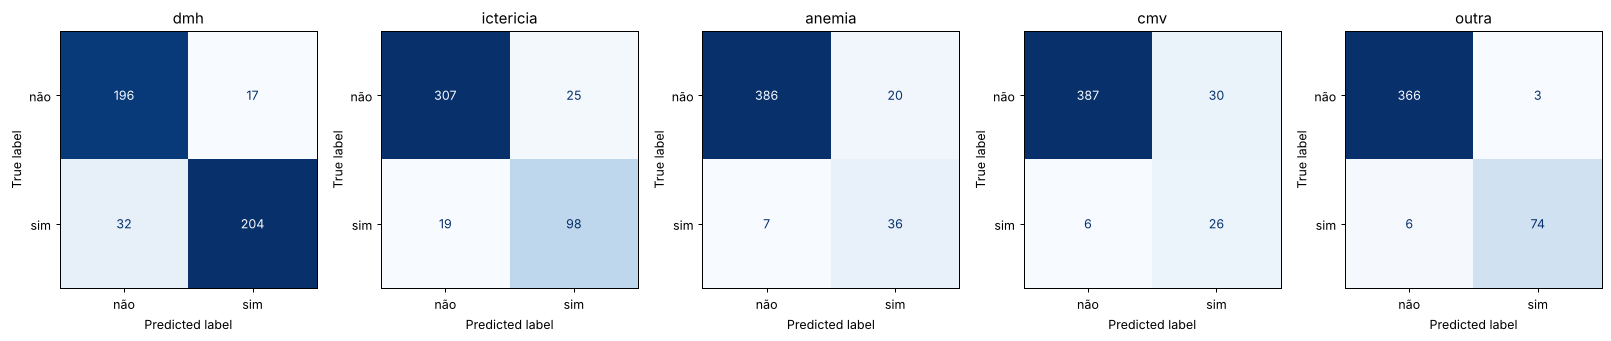

=== dmh ===
              precision    recall  f1-score   support

         não      0.860     0.920     0.889       213
         sim      0.923     0.864     0.893       236

    accuracy                          0.891       449
   macro avg      0.891     0.892     0.891       449
weighted avg      0.893     0.891     0.891       449

=== ictericia ===
              precision    recall  f1-score   support

         não      0.942     0.925     0.933       332
         sim      0.797     0.838     0.817       117

    accuracy                          0.902       449
   macro avg      0.869     0.881     0.875       449
weighted avg      0.904     0.902     0.903       449

=== anemia ===
              precision    recall  f1-score   support

         não      0.982     0.951     0.966       406
         sim      0.643     0.837     0.727        43

    accuracy                          0.940       449
   macro avg      0.813     0.894     0.847       449
weighted avg      0.950     0

In [10]:
fig, axes = plt.subplots(1, len(ALVOS), figsize=(18, 3.6))
for ax, a in zip(axes, ALVOS):
    y = d[a].to_numpy()
    ConfusionMatrixDisplay(confusion_matrix(y, previsoes_finais[a][1]), display_labels=["não", "sim"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(a[4:])
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_matrizes_confusao.png", dpi=200, bbox_inches="tight")
plt.show()

for a in ALVOS:
    print(f"=== {a[4:]} ===")
    print(classification_report(d[a], previsoes_finais[a][1], target_names=["não", "sim"], digits=3))

### Variáveis mais importantes

Na regressão logística, cada coeficiente indica quanto sobe (positivo) ou desce (negativo) a probabilidade da patologia quando a variável aumenta um desvio-padrão. O modelo é treinado com todos os dias.

,dmh,ictericia,anemia,cmv,outra
ontem_outra,-0.13,-0.29,0.36,-0.37,1.88
ontem_dmh,1.71,0.20,-0.34,-0.79,-0.08
ontem_ictericia,0.22,1.56,-0.55,-0.38,0.12
ontem_anemia,-0.21,-0.35,1.35,-0.28,0.11
ontem_cmv,-0.40,-0.18,-0.39,1.16,-0.28
ontem_registo,0.08,0.09,0.11,-0.64,-0.02
dia_internamento,-0.07,-0.32,0.40,0.10,0.08
dia_completo,0.08,0.40,-0.03,-0.06,0.26
perfusion_delta,0.04,0.07,-0.38,0.22,-0.11
sat_o2_tendencia,-0.14,-0.02,-0.12,0.37,0.17


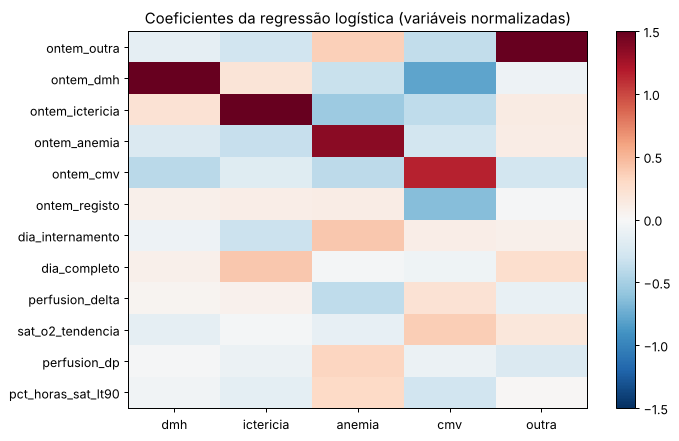

In [11]:
modelos_finais, coef = {}, {}
for a in ALVOS:
    m = fabrica_final().fit(d[VARS_FINAL], d[a])
    modelos_finais[a] = m
    coef[a[4:]] = m[-1].coef_[0]
coef = pd.DataFrame(coef, index=VARS_FINAL)
top = coef.abs().max(axis=1).sort_values(ascending=False).head(12).index
display(coef.loc[top].round(2))

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(coef.loc[top], cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set(xticks=range(len(ALVOS)), xticklabels=coef.columns, yticks=range(len(top)), yticklabels=top,
       title="Coeficientes da regressão logística (variáveis normalizadas)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_coeficientes.png", dpi=200, bbox_inches="tight")
plt.show()

## 6.1 Avaliar os resultados face aos critérios de sucesso (Tabela 8)

Os critérios por patologia aplicam-se às quatro patologias modeladas; "outra" entra no F1-macro.

In [12]:
f = final.set_index("patologia")
modeladas = ["dmh", "ictericia", "anemia", "cmv"]
criterios = pd.DataFrame([
    ("F1-macro >= 0,50", f"{f['F1'].mean():.3f}", f["F1"].mean() >= 0.50),
    ("ROC-AUC >= 0,70 em cada patologia modelada", f"mín. {f.loc[modeladas, 'AUC'].min():.3f}", (f.loc[modeladas, "AUC"] >= 0.70).all()),
    ("kappa >= 0,40 em cada patologia modelada", f"mín. {f.loc[modeladas, 'kappa'].min():.3f}", (f.loc[modeladas, "kappa"] >= 0.40).all()),
    ("recall >= 0,70 na DMH", f"{f.loc['dmh', 'recall']:.3f}", f.loc["dmh", "recall"] >= 0.70),
    ("recall >= 0,70 na icterícia", f"{f.loc['ictericia', 'recall']:.3f}", f.loc["ictericia", "recall"] >= 0.70),
], columns=["critério", "valor obtido", "cumprido"])
criterios["cumprido"] = criterios["cumprido"].map({True: "✔", False: "✘"})
criterios

,critério,valor obtido,cumprido
0,"F1-macro >= 0,50",0.793,✔
1,"ROC-AUC >= 0,70 em cada patologia modelada",mín. 0.906,✔
2,"kappa >= 0,40 em cada patologia modelada",mín. 0.538,✔
3,"recall >= 0,70 na DMH",0.860,✔
4,"recall >= 0,70 na icterícia",0.826,✔


**Leitura dos resultados (para o capítulo 6):**

- **Só com sinais vitais (cenário A), os modelos ficam perto do acaso.** O melhor F1-macro é cerca de 0,32 contra 0,23 do baseline, com AUC média de cerca de 0,55. A saturação, o pulso e a perfusão de um dia quase não distinguem as patologias. É um resultado legítimo e deve ser reportado como tal.
- **Com as patologias de ontem (cenário B), todos os critérios ficam ao alcance.** As patologias duram vários dias, por isso o diagnóstico de ontem é o melhor indicador do de hoje. O ganho do modelo está sobretudo em detetar o início e o fim de cada patologia, e é aí que os sinais vitais podem ajudar.
- **O modelo simples ganha.** Com 47 bebés, a regressão logística é mais estável do que a Random Forest ou a rede neuronal, sobretudo no CMV, a patologia mais difícil (F1 cerca de 0,58).
- **Ajustar o limiar não compensa** com tão poucos casos das patologias raras. Fica 0,5.
- **Decisão para o relatório:** se o grupo ficar com o cenário B, a Tabela 7 (objetivo de classificação) deve ser atualizada para "a partir dos sinais vitais do dia e das patologias registadas no dia anterior", e a construção das variáveis `ontem_*` deve passar para o notebook 02.

## Guardar o modelo final (para o Projeto 2)

In [13]:
joblib.dump({"modelos": modelos_finais, "limiares": {a: LIMIAR_FINAL for a in ALVOS}, "variaveis": VARS_FINAL,
             "cenario": CENARIO_FINAL, "algoritmo": NOME_FINAL}, MODEL_DIR / "modelo_classificacao.joblib")
saida = d[["episodio", "data"] + ALVOS].copy()
for a in ALVOS:
    saida[f"prob_{a}"] = previsoes_finais[a][0].round(4)
    saida[f"prev_{a}"] = previsoes_finais[a][1]
saida.to_csv(PROC_DIR / "previsoes_classificacao.csv", index=False)
print("Guardado:", MODEL_DIR / "modelo_classificacao.joblib")
print("Guardado:", PROC_DIR / "previsoes_classificacao.csv")

Guardado: /home/claude/proj/models/modelo_classificacao.joblib
Guardado: /home/claude/proj/data/processed/previsoes_classificacao.csv
